# Baselines

In [2]:
import pandas as pd
import numpy as np
from sklearn.model_selection import LeaveOneGroupOut
from sklearn.dummy import DummyClassifier
from sklearn.linear_model import LogisticRegression
from sklearn.preprocessing import StandardScaler
from sklearn.metrics import accuracy_score, precision_score, recall_score, f1_score

# Cargar los datos
df = pd.read_csv("features_dataset_bilateral.csv")

# Extraer características obligatorias para el baseline (Sección 5.1)
# El baseline no sufre por los NaNs porque usamos solo RMS y MDF
X = df[['RMS', 'MDF']].values
y = df['label'].values
groups = df['sujeto'].values

# Inicializar modelos base
dummy = DummyClassifier(strategy='most_frequent')
# class_weight='balanced' para manejar el ligero desbalance de clases (Sección 5.3)
log_reg = LogisticRegression(class_weight='balanced', random_state=42, max_iter=1000)

logo = LeaveOneGroupOut()

results_dummy = {'acc': [], 'prec': [], 'rec': [], 'f1': []}
results_lr = {'acc': [], 'prec': [], 'rec': [], 'f1': []}

for train_idx, test_idx in logo.split(X, y, groups):
    X_train, X_test = X[train_idx], X[test_idx]
    y_train, y_test = y[train_idx], y[test_idx]
    
    # IMPORTANTE: El escalado (Normalización) se ajusta SOLO en el entrenamiento para evitar fugas de datos
    scaler = StandardScaler()
    X_train_scaled = scaler.fit_transform(X_train)
    X_test_scaled = scaler.transform(X_test)
    
    # Entrenar y evaluar Dummy (Baseline 1)
    dummy.fit(X_train, y_train)
    y_pred_dummy = dummy.predict(X_test)
    results_dummy['acc'].append(accuracy_score(y_test, y_pred_dummy))
    results_dummy['prec'].append(precision_score(y_test, y_pred_dummy, average='macro', zero_division=0))
    results_dummy['rec'].append(recall_score(y_test, y_pred_dummy, average='macro', zero_division=0))
    results_dummy['f1'].append(f1_score(y_test, y_pred_dummy, average='macro', zero_division=0))
    
    # Entrenar y evaluar Regresión Logística (Baseline 2)
    log_reg.fit(X_train_scaled, y_train)
    y_pred_lr = log_reg.predict(X_test_scaled)
    results_lr['acc'].append(accuracy_score(y_test, y_pred_lr))
    results_lr['prec'].append(precision_score(y_test, y_pred_lr, average='macro', zero_division=0))
    results_lr['rec'].append(recall_score(y_test, y_pred_lr, average='macro', zero_division=0))
    results_lr['f1'].append(f1_score(y_test, y_pred_lr, average='macro', zero_division=0))

# Calcular media y desviación estándar para el reporte
def summarize(res):
    return {k: f"{np.mean(v):.4f} +/- {np.std(v):.4f}" for k, v in res.items()}

print("Resultados Baseline 1 (Clase Mayoritaria):")
for k, v in summarize(results_dummy).items(): print(f"  {k}: {v}")

print("\nResultados Baseline 2 (Regresión Logística con RMS y MDF):")
for k, v in summarize(results_lr).items(): print(f"  {k}: {v}")

Resultados Baseline 1 (Clase Mayoritaria):
  acc: 0.3587 +/- 0.0168
  prec: 0.1196 +/- 0.0056
  rec: 0.3333 +/- 0.0000
  f1: 0.1759 +/- 0.0061

Resultados Baseline 2 (Regresión Logística con RMS y MDF):
  acc: 0.4034 +/- 0.0317
  prec: 0.3871 +/- 0.0146
  rec: 0.3882 +/- 0.0295
  f1: 0.3604 +/- 0.0343


# Base de datos

In [3]:
import pandas as pd
import matplotlib.pyplot as plt
from scipy.signal import find_peaks
from scipy.ndimage import gaussian_filter1d
import os

# 1. Crear directorio general para todas las gráficas
output_dir = 'graficas_todos_los_sujetos'
if not os.path.exists(output_dir):
    os.makedirs(output_dir)

# 2. Cargar dataset completo
df = pd.read_csv('features_dataset_bilateral.csv')

# 3. Agrupar por sujeto, repetición (serie) y lado
grupos = df.groupby(['sujeto', 'repeticion', 'lado'])

bg_color = '#E8E8F2' 

# 4. Iterar sobre todos los sujetos, series y lados
for (sujeto, repeticion, lado), datos_grupo in grupos:
    datos = datos_grupo.sort_values('time_s')
    tiempo = datos['time_s'].values
    senal = datos['RMS'].values 
    
    # Suavizar la señal con filtro gaussiano
    senal_suavizada = gaussian_filter1d(senal, sigma=2)
    
    # Encontrar picos sobre la señal suavizada
    picos, _ = find_peaks(senal_suavizada, distance=5, prominence=0.3) 
    
    fig, (ax1, ax2) = plt.subplots(2, 1, figsize=(12, 7), sharex=True)
    fig.patch.set_facecolor(bg_color)
    fig.suptitle(f'Sujeto: {sujeto} | Serie: {repeticion} | Lado: {lado.capitalize()}', 
                 fontsize=14, fontweight='bold')
    
    # SUBPLOT 1: Señal Original (RMS)
    ax1.plot(tiempo, senal, color='#5c6b8c', linewidth=1.5)
    ax1.set_ylabel('Amplitud (RMS)')
    ax1.set_title('Señal Original (RMS)', loc='left', fontsize=10)
    ax1.set_facecolor(bg_color)
    ax1.grid(True, color='white', linestyle='-', linewidth=1.5)
    
    # SUBPLOT 2: Envolvente Suavizada + Picos
    ax2.plot(tiempo, senal_suavizada, color='#5c6b8c', linewidth=1.5, label='Envolvente suavizada')
    
    
    ax2.set_xlabel('Tiempo (s)')
    ax2.set_ylabel('Amplitud Suavizada')
    ax2.set_title('Señal Suavizada', loc='left', fontsize=10)
    ax2.set_facecolor(bg_color)
    ax2.grid(True, color='white', linestyle='-', linewidth=1.5)
    ax2.legend(loc='upper right')
    
    plt.tight_layout()
    
    # Guardar imagen con el nombre de cada sujeto
    nombre_archivo = f"{output_dir}/{sujeto}_{repeticion}_{lado}.png"
    plt.savefig(nombre_archivo, dpi=150, facecolor=fig.get_facecolor())
    plt.close()

print(f"¡Proceso terminado! Se generaron y guardaron todas las imágenes en la carpeta '{output_dir}'.")

¡Proceso terminado! Se generaron y guardaron todas las imágenes en la carpeta 'graficas_todos_los_sujetos'.


In [4]:
import pandas as pd

# 1. Cargar la base de datos original
df = pd.read_csv('features_dataset_bilateral.csv')
filas_originales = len(df)

# 2. Identificar las filas exactas que queremos eliminar
# Usamos .astype(str).str.contains() para que funcione sin importar si tu columna 
# dice "4" o "R4", y si tu lado dice "iz", "izq" o "izquierda".

# Sujeto 14: Pierna izquierda, R4 y R5
cond_s14_izq = (df['sujeto'] == 'sujeto14') & (df['lado'].str.startswith('iz'))
excluir_s14 = cond_s14_izq & (df['repeticion'].astype(str).str.contains('4') | df['repeticion'].astype(str).str.contains('5'))

# Sujeto 15: Pierna derecha, R1, R2 y R3
cond_s15_der = (df['sujeto'] == 'sujeto15') & (df['lado'].str.startswith('d'))
excluir_s15 = cond_s15_der & (df['repeticion'].astype(str).str.contains('1') | df['repeticion'].astype(str).str.contains('2') | df['repeticion'].astype(str).str.contains('3'))

# 3. Combinar todas las exclusiones
filas_a_eliminar = excluir_s14 | excluir_s15

# 4. Crear el nuevo dataset conservando solo las filas que NO (~) están en la lista de eliminación
df_limpio = df[~filas_a_eliminar]

# 5. Guardar la nueva base de datos en tu computadora
nuevo_nombre = 'features_dataset_limpio.csv'
df_limpio.to_csv(nuevo_nombre, index=False)

# Mostrar el resumen de lo que se hizo
print(f"Dataset original: {filas_originales} filas.")
print(f"Filas eliminadas: {filas_a_eliminar.sum()} filas correspondientes a tus exclusiones.")
print(f"Nuevo dataset: {len(df_limpio)} filas.")
print(f"¡El archivo se ha guardado exitosamente en tu computadora como '{nuevo_nombre}'!")

Dataset original: 31021 filas.
Filas eliminadas: 965 filas correspondientes a tus exclusiones.
Nuevo dataset: 30056 filas.
¡El archivo se ha guardado exitosamente en tu computadora como 'features_dataset_limpio.csv'!


In [5]:
import pandas as pd

# Cargar el dataset original
df = pd.read_csv("features_dataset_limpio.csv")

# Definir las columnas numéricas a suavizar
smooth_cols = ['RMS', 'MAV', 'WL', 'MDF', 'MNF', 'RMS_ratio_dr_iz', 'MDF_diff_dr_iz']

# Crear una copia para los nuevos sujetos
df_new = df.copy()

# Aplicar suavizado (media móvil de ventana 5) agrupando por sujeto, repetición y lado
# min_periods=1 evita que se generen valores nulos al inicio de cada serie
df_new[smooth_cols] = df_new.groupby(['sujeto', 'repeticion', 'lado'])[smooth_cols].transform(
    lambda x: x.rolling(window=5, min_periods=1).mean()
)

# Renombrar los sujetos (1->16, 2->17, ..., 15->30)
def map_subject(s):
    num = int(s.replace('sujeto', ''))
    return f'sujeto{num + 15}'

df_new['sujeto'] = df_new['sujeto'].apply(map_subject)

# Concatenar el dataset original con el nuevo
df_combined = pd.concat([df, df_new], ignore_index=True)

# Guardar el nuevo dataset
output_file = "features_dataset_bilateral_suavizado.csv"
df_combined.to_csv(output_file, index=False)

# Mostrar resumen
print(f"Dataset original: {df.shape[0]} filas")
print(f"Nuevos datos (sujetos 16-30 suavizados): {df_new.shape[0]} filas")
print(f"Dataset combinado final: {df_combined.shape[0]} filas")
print(f"Sujetos añadidos: {sorted(df_new['sujeto'].unique(), key=lambda x: int(x.replace('sujeto', '')))}")

Dataset original: 30056 filas
Nuevos datos (sujetos 16-30 suavizados): 30056 filas
Dataset combinado final: 60112 filas
Sujetos añadidos: ['sujeto16', 'sujeto17', 'sujeto18', 'sujeto19', 'sujeto20', 'sujeto21', 'sujeto22', 'sujeto23', 'sujeto24', 'sujeto25', 'sujeto26', 'sujeto27', 'sujeto28', 'sujeto29', 'sujeto30']


In [6]:
import pandas as pd

# Cargar el dataset anterior que contiene los sujetos 1 al 30
df_combined = pd.read_csv("features_dataset_bilateral_suavizado.csv")

# Separar los datos originales (1-15) y los suavizados (16-30)
df_raw = df_combined[df_combined['sujeto'].isin([f'sujeto{i}' for i in range(1, 16)])].reset_index(drop=True)
df_smooth = df_combined[df_combined['sujeto'].isin([f'sujeto{i}' for i in range(16, 31)])].reset_index(drop=True)

# Crear una copia para los nuevos sujetos interpolados
df_interp = df_raw.copy()

# Definir las columnas numéricas
num_cols = ['RMS', 'MAV', 'WL', 'MDF', 'MNF', 'RMS_ratio_dr_iz', 'MDF_diff_dr_iz']

# Generar la interpolación: el punto medio (promedio) entre la señal cruda y la señal suavizada
df_interp[num_cols] = (df_raw[num_cols] + df_smooth[num_cols]) / 2.0

# Renombrar los sujetos (1->31, ..., 15->45)
def map_subject_to_interp(s):
    num = int(s.replace('sujeto', ''))
    return f'sujeto{num + 30}'

df_interp['sujeto'] = df_interp['sujeto'].apply(map_subject_to_interp)

# Concatenar todo para tener del sujeto 1 al 45
df_final = pd.concat([df_combined, df_interp], ignore_index=True)

# Guardar el nuevo dataset
output_file = "features_dataset_bilateral_interpolado.csv"
df_final.to_csv(output_file, index=False)

print(f"Filas originales + suavizadas: {df_combined.shape[0]}")
print(f"Filas interpoladas agregadas (sujetos 31-45): {df_interp.shape[0]}")
print(f"Total de filas en el nuevo dataset: {df_final.shape[0]}")
print(f"Sujetos generados: {sorted(df_interp['sujeto'].unique(), key=lambda x: int(x.replace('sujeto', '')))}")

Filas originales + suavizadas: 60112
Filas interpoladas agregadas (sujetos 31-45): 30056
Total de filas en el nuevo dataset: 90168
Sujetos generados: ['sujeto31', 'sujeto32', 'sujeto33', 'sujeto34', 'sujeto35', 'sujeto36', 'sujeto37', 'sujeto38', 'sujeto39', 'sujeto40', 'sujeto41', 'sujeto42', 'sujeto43', 'sujeto44', 'sujeto45']


Analisis de datos 

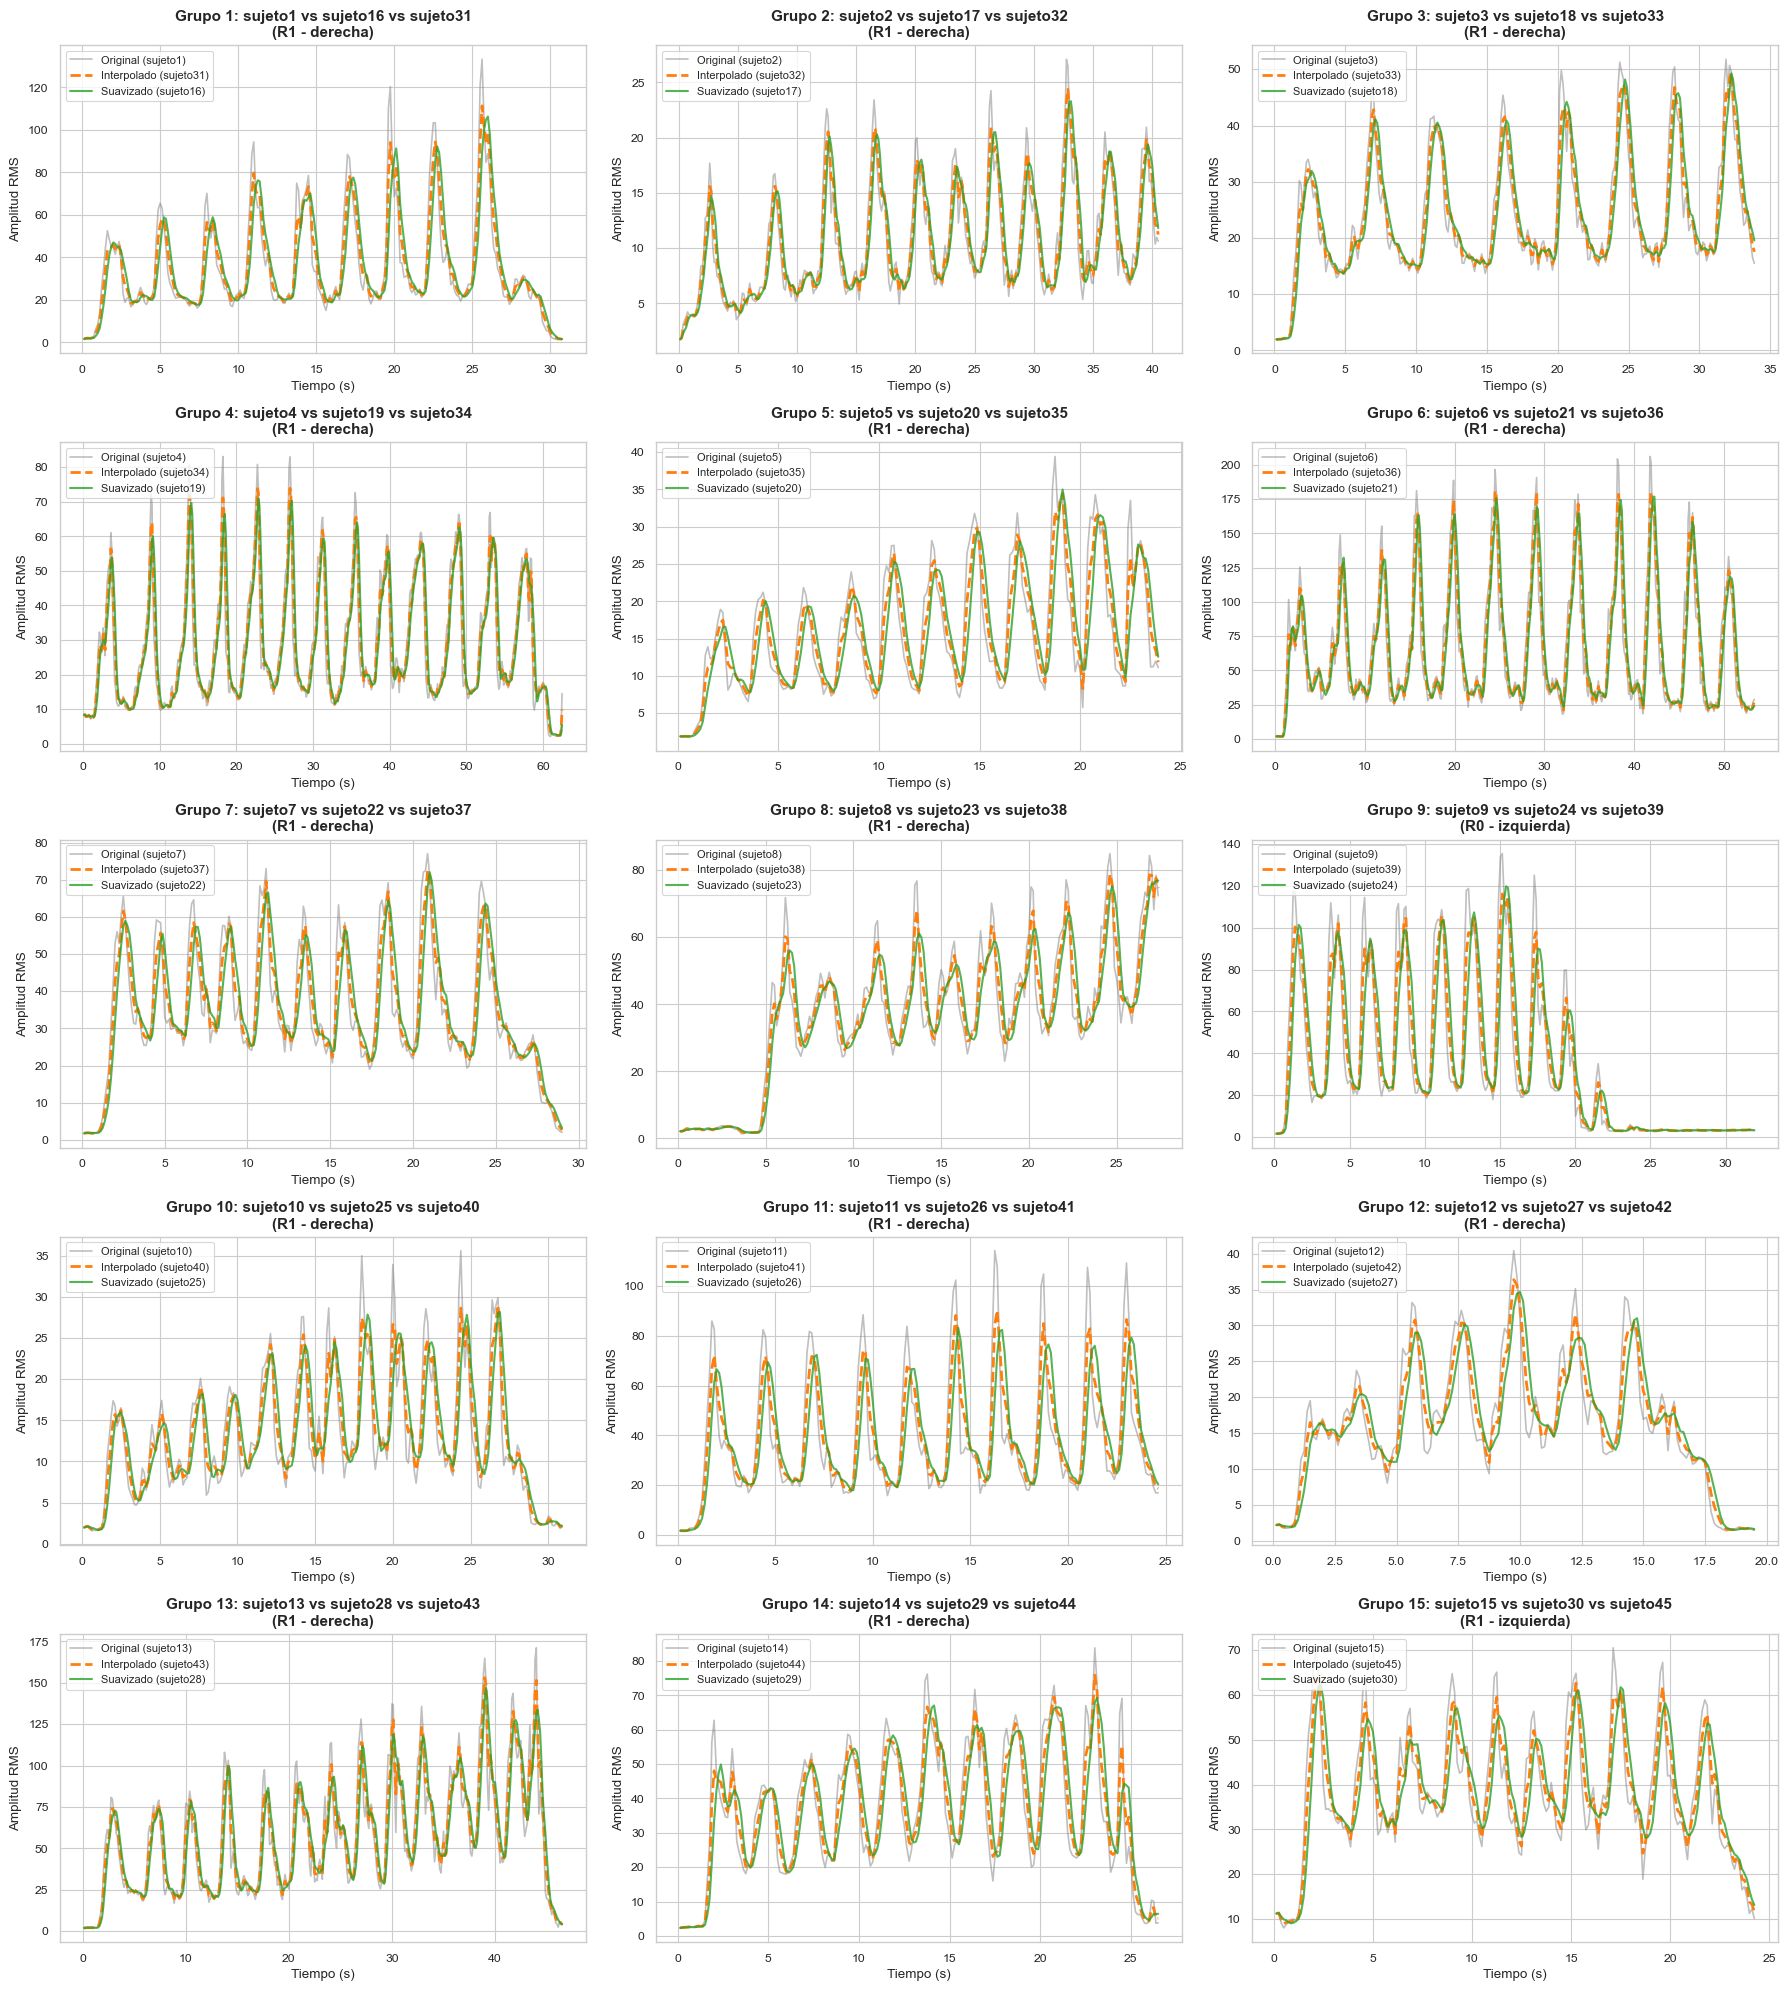

Desviación estándar de RMS (medida de dispersión/ruido) por variante:
 Grupo_Base  Std_Original  Std_Interpolado  Std_Suavizado
          1         23.76            21.80          21.65
          2          7.03             6.60           6.56
          3         13.37            12.59          12.55
          4         21.57            20.40          20.30
          5          8.57             7.62           7.56
          6         41.09            37.37          37.04
          7         20.06            18.30          18.11
          8         24.66            23.10          22.93
          9         36.70            31.80          31.19
         10          8.04             7.32           7.25
         11         33.38            27.08          26.18
         12         12.48            11.46          11.35
         13         37.38            34.58          34.28
         14         25.43            22.41          22.00
         15         19.36            16.89          16.54


In [7]:
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

# Cargar los datos
df = pd.read_csv("features_dataset_bilateral_interpolado.csv")

# Configurar la cuadrícula de gráficos (5 filas x 3 columnas para los 15 grupos)
sns.set_theme(style="whitegrid", context="paper")
fig, axes = plt.subplots(5, 3, figsize=(18, 20))
axes = axes.flatten()

stats = []

for i in range(1, 16):
    ax = axes[i-1]
    
    # Identificadores de cada triplete
    s_orig = f"sujeto{i}"
    s_suav = f"sujeto{i+15}"
    s_intp = f"sujeto{i+30}"
    
    # Para comparar consistentemente, tomamos la primera repetición disponible de cada sujeto
    temp_df = df[df['sujeto'] == s_orig]
    if len(temp_df) == 0: continue
    rep = temp_df['repeticion'].iloc[0]
    lado = temp_df['lado'].iloc[0]
    
    df_orig = temp_df[(temp_df['repeticion'] == rep) & (temp_df['lado'] == lado)]
    df_suav = df[(df['sujeto'] == s_suav) & (df['repeticion'] == rep) & (df['lado'] == lado)]
    df_intp = df[(df['sujeto'] == s_intp) & (df['repeticion'] == rep) & (df['lado'] == lado)]
    
    # Graficar la característica RMS para la comparación visual del ruido
    ax.plot(df_orig['time_s'], df_orig['RMS'], label=f'Original ({s_orig})', alpha=0.5, color='gray')
    ax.plot(df_intp['time_s'], df_intp['RMS'], label=f'Interpolado ({s_intp})', linestyle='--', linewidth=2, color='tab:orange')
    ax.plot(df_suav['time_s'], df_suav['RMS'], label=f'Suavizado ({s_suav})', alpha=0.8, linewidth=1.5, color='tab:green')
    
    ax.set_title(f"Grupo {i}: {s_orig} vs {s_suav} vs {s_intp}\n({rep} - {lado})", fontsize=11, fontweight='bold')
    ax.set_xlabel("Tiempo (s)")
    ax.set_ylabel("Amplitud RMS")
    ax.legend(fontsize=8, loc='upper left')
    
    # Recopilar métricas de desviación estándar global (ruido) para el reporte
    std_orig = df[df['sujeto'] == s_orig]['RMS'].std()
    std_suav = df[df['sujeto'] == s_suav]['RMS'].std()
    std_intp = df[df['sujeto'] == s_intp]['RMS'].std()
    stats.append((i, std_orig, std_intp, std_suav))

plt.tight_layout()
plt.savefig("comparacion_tripletas.png", dpi=300, bbox_inches="tight")
plt.show()

# Mostrar la tabla de resumen estadístico de la reducción de ruido
stats_df = pd.DataFrame(stats, columns=['Grupo_Base', 'Std_Original', 'Std_Interpolado', 'Std_Suavizado'])
print("Desviación estándar de RMS (medida de dispersión/ruido) por variante:")
print(stats_df.round(2).to_string(index=False))

# Random Forest 

--------------------------------------------------
Accuracy Global: 0.7553
F1-Score (Macro): 0.7554
--------------------------------------------------
Reporte por Clases
              precision    recall  f1-score   support

           0       0.81      0.82      0.82      6475
           1       0.68      0.71      0.70      6470
           2       0.79      0.72      0.75      4915

    accuracy                           0.76     17860
   macro avg       0.76      0.75      0.76     17860
weighted avg       0.76      0.76      0.76     17860

--------------------------------------------------


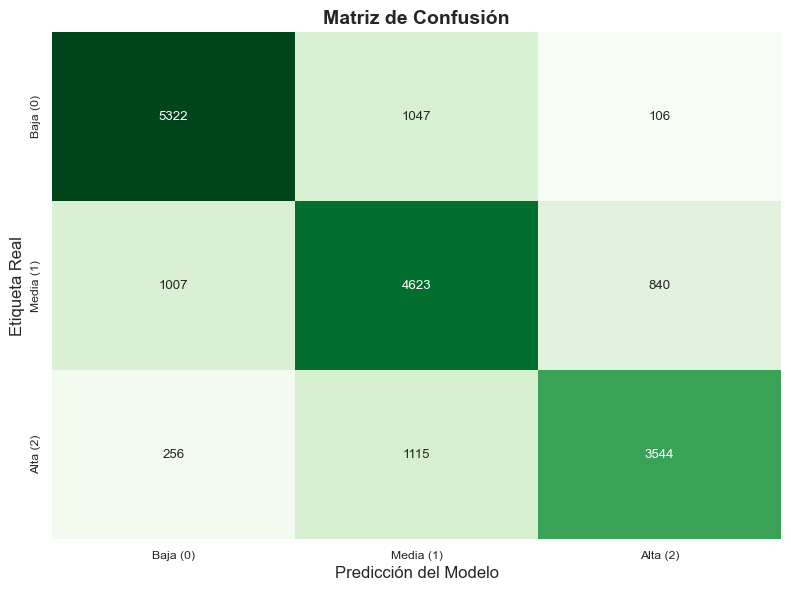

In [8]:
import pandas as pd
import numpy as np
import random
import matplotlib.pyplot as plt
import seaborn as sns
from sklearn.ensemble import RandomForestClassifier
from sklearn.metrics import accuracy_score, classification_report, confusion_matrix, f1_score

# 1. Cargar el dataset
df = pd.read_csv('features_dataset_bilateral_interpolado.csv')

# Imputar nulos en características bilaterales con la mediana
df['RMS_ratio_dr_iz'] = df['RMS_ratio_dr_iz'].fillna(df['RMS_ratio_dr_iz'].median())
df['MDF_diff_dr_iz'] = df['MDF_diff_dr_iz'].fillna(df['MDF_diff_dr_iz'].median())

# Ordenar cronológicamente para calcular correctamente las ventanas de tiempo
df = df.sort_values(['sujeto', 'repeticion', 'lado', 'time_s'])

# 2. Ingeniería de Características (Z-Score, Derivada y Memoria Temporal)
cols_to_norm = ['RMS', 'MAV', 'WL', 'MDF', 'MNF']
for col in cols_to_norm:
    df[f'{col}_z'] = df.groupby(['sujeto', 'lado'])[col].transform(lambda x: (x - x.mean()) / x.std())

for col in ['RMS', 'MDF']:
    df[f'{col}_slope'] = df.groupby(['sujeto', 'repeticion', 'lado'])[col].diff().fillna(0)

for col in ['MDF_z', 'RMS_z']:
    df[f'{col}_roll10'] = df.groupby(['sujeto', 'repeticion', 'lado'])[col].transform(lambda x: x.rolling(10, min_periods=1).mean())

# 3. Separación estricta por sujetos (80% Train / 20% Test)
np.random.seed(42)
random.seed(42)
sujetos = df['sujeto'].unique()
train_sujetos = np.random.choice(sujetos, size=36, replace=False)
test_sujetos = [s for s in sujetos if s not in train_sujetos]

features = ['RMS_ratio_dr_iz', 'MDF_diff_dr_iz'] + [f'{c}_z' for c in cols_to_norm] + ['RMS_slope', 'MDF_slope', 'MDF_z_roll10', 'RMS_z_roll10']

X_train = df[df['sujeto'].isin(train_sujetos)][features]
y_train = df[df['sujeto'].isin(train_sujetos)]['label']
X_test = df[df['sujeto'].isin(test_sujetos)][features]
y_test = df[df['sujeto'].isin(test_sujetos)]['label']

# 4. Entrenar el Random Forest
rf = RandomForestClassifier(n_estimators=150, max_depth=25, class_weight='balanced', random_state=42, n_jobs=-1)
rf.fit(X_train, y_train)
y_pred = rf.predict(X_test)

# 5. Calcular Métricas para la Tabla 6.1 y 6.2 del reporte
accuracy = accuracy_score(y_test, y_pred)
macro_f1 = f1_score(y_test, y_pred, average='macro')
report = classification_report(y_test, y_pred)

print("-" * 50)
print(f"Accuracy Global: {accuracy:.4f}")
print(f"F1-Score (Macro): {macro_f1:.4f}")
print("-" * 50)
print("Reporte por Clases")
print(report)
print("-" * 50)

# 6. Matriz de Confusión (Valores absolutos para la sección 6.3)
cm = confusion_matrix(y_test, y_pred)

plt.figure(figsize=(8, 6))
# fmt='d' asegura que salgan números enteros (conteos absolutos) y no porcentajes ni notación científica
sns.heatmap(cm, annot=True, fmt='d', cmap='Greens', cbar=False,
            xticklabels=['Baja (0)', 'Media (1)', 'Alta (2)'],
            yticklabels=['Baja (0)', 'Media (1)', 'Alta (2)'])

plt.title('Matriz de Confusión', fontsize=14, fontweight='bold')
plt.xlabel('Predicción del Modelo', fontsize=12)
plt.ylabel('Etiqueta Real', fontsize=12)
plt.tight_layout()

plt.savefig('confusion_matrix_rf_absolute.png', dpi=300)
plt.show()

C:\Users\Ep1001\AppData\Local\Temp\ipykernel_29496\577688949.py:22: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.

  ax = sns.barplot(x=nombres_sujetos, y=valores_f1, palette="viridis")


¡Imagen per_subject_f1.png generada con éxito!


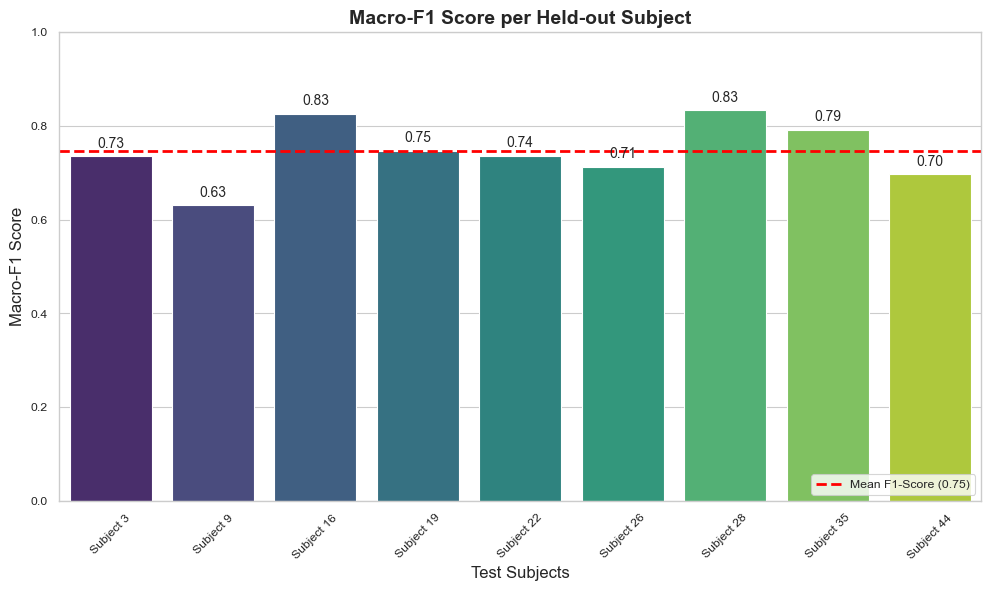

In [9]:
from sklearn.metrics import f1_score

# 1. Calcular F1-Score macro para cada sujeto de prueba
f1_scores = {}
test_sujetos_sorted = sorted(test_sujetos, key=lambda x: int(x.replace('sujeto', '')))

for subj in test_sujetos_sorted:
    X_test_subj = df[df['sujeto'] == subj][features]
    y_test_subj = df[df['sujeto'] == subj]['label']
    
    y_pred_subj = rf.predict(X_test_subj)
    f1_scores[subj] = f1_score(y_test_subj, y_pred_subj, average='macro')

# 2. Crear la gráfica de barras verticales
plt.figure(figsize=(10, 6))
sns.set_style("whitegrid")

nombres_sujetos = [s.replace('sujeto', 'Subject ') for s in f1_scores.keys()]
valores_f1 = list(f1_scores.values())
mean_f1 = np.mean(valores_f1)

ax = sns.barplot(x=nombres_sujetos, y=valores_f1, palette="viridis")
plt.axhline(mean_f1, color='red', linestyle='--', linewidth=2, label=f'Mean F1-Score ({mean_f1:.2f})')

plt.ylim(0, 1.0)
plt.title('Macro-F1 Score per Held-out Subject', fontsize=14, fontweight='bold')
plt.ylabel('Macro-F1 Score', fontsize=12)
plt.xlabel('Test Subjects', fontsize=12)
plt.xticks(rotation=45)
plt.legend(loc='lower right')

# Añadir el valor exacto sobre cada barra
for p in ax.patches:
    ax.annotate(format(p.get_height(), '.2f'), 
                (p.get_x() + p.get_width() / 2., p.get_height()), 
                ha='center', va='center', 
                xytext=(0, 9), 
                textcoords='offset points',
                fontsize=10)

plt.tight_layout()
plt.savefig('per_subject_f1.png', dpi=300)
print("¡Imagen per_subject_f1.png generada con éxito!")
plt.show()

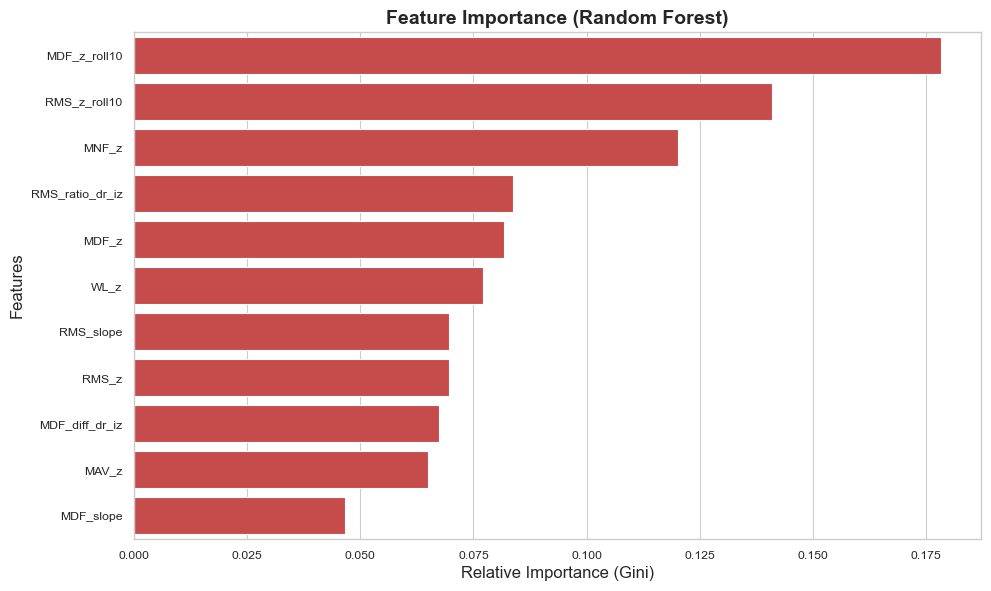

In [10]:

importancias = rf.feature_importances_
indices = np.argsort(importancias)[::-1]
nombres_ordenados = [features[i] for i in indices]
valores_ordenados = importancias[indices]

# Graficar
plt.figure(figsize=(10, 6))
sns.barplot(x=valores_ordenados, y=nombres_ordenados, color="#DA3737")

plt.title('Feature Importance (Random Forest)', fontsize=14, fontweight='bold')
plt.xlabel('Relative Importance (Gini)', fontsize=12)
plt.ylabel('Features', fontsize=12)
plt.tight_layout()

# Guardar la imagen para Overleaf
plt.savefig('feature_importance1.png', dpi=300)
plt.show()

In [19]:
import joblib

# Guardar el modelo entrenado en un archivo .pkl
joblib.dump(rf, 'modelo_fatiga_rf.pkl')
print("¡Modelo guardado exitosamente como 'modelo_fatiga_rf.pkl'!")

¡Modelo guardado exitosamente como 'modelo_fatiga_rf.pkl'!


# Tratamiento de la señal de prueba 

In [17]:
import pandas as pd
import numpy as np
from scipy.signal import welch

print("Iniciando extracción de características...")

# 1. Cargar la señal cruda
df_raw = pd.read_csv('datos_nuevo_paciente.csv')

# 2. Configuración de las ventanas (Basado en tu protocolo de 1000 Hz)
fs = 1000  # Frecuencia de muestreo (1000 Hz)
window_length = 500  # Ventanas de 0.5 segundos (500 muestras)

caracteristicas = []

# 3. Procesar la señal por ventanas
for i in range(0, len(df_raw), window_length):
    ventana = df_raw.iloc[i : i + window_length]
    
    # Ignorar la última ventana si quedó incompleta
    if len(ventana) < window_length:
        break
        
    voltajes = ventana['Voltage_mV'].values
    tiempo_actual = ventana['Relative_Time_s'].values[-1] # Tiempo al final de la ventana
    
    # -- DOMINIO DEL TIEMPO --
    # 1. Root Mean Square (RMS)
    rms = np.sqrt(np.mean(voltajes**2))
    # 2. Mean Absolute Value (MAV)
    mav = np.mean(np.abs(voltajes))
    # 3. Waveform Length (WL)
    wl = np.sum(np.abs(np.diff(voltajes)))
    
    # -- DOMINIO DE LA FRECUENCIA --
    # Calcular la Densidad Espectral de Potencia (PSD)
    freqs, psd = welch(voltajes, fs=fs, nperseg=len(voltajes))
    suma_psd = np.sum(psd)
    
    if suma_psd > 0:
        # 4. Mean Frequency (MNF)
        mnf = np.sum(freqs * psd) / suma_psd
        
        # 5. Median Frequency (MDF)
        potencia_acumulada = np.cumsum(psd)
        mdf_index = np.where(potencia_acumulada >= suma_psd / 2)[0][0]
        mdf = freqs[mdf_index]
    else:
        mnf, mdf = 0, 0
        
    # Guardar los datos de esta ventana
    caracteristicas.append({
        'time_s': tiempo_actual,
        'RMS': rms,
        'MAV': mav,
        'WL': wl,
        'MDF': mdf,
        'MNF': mnf
    })

# 4. Convertir los resultados en una tabla y guardarla
df_features = pd.DataFrame(caracteristicas)
nuevo_archivo = 'features_nuevo_paciente.csv'
df_features.to_csv(nuevo_archivo, index=False)

print(f"¡Procesamiento exitoso! Se analizó la señal y se guardó como: {nuevo_archivo}")
print("Primeras filas del nuevo archivo listo para el modelo:")
print(df_features.head())

Iniciando extracción de características...
¡Procesamiento exitoso! Se analizó la señal y se guardó como: features_nuevo_paciente.csv
Primeras filas del nuevo archivo listo para el modelo:
   time_s        RMS       MAV       WL    MDF         MNF
0     0.5   2.445354   1.88802   959.05  110.0  166.604469
1     1.0   4.660328   3.44508  1092.90   46.0   99.577121
2     1.5  13.850785  10.74722  2407.96   46.0   60.985173
3     2.0  14.983376  11.94620  2901.98   52.0   75.555866
4     2.5  21.613384  17.38748  4147.83   54.0   66.610892


Iniciando carga de datos y predicción...


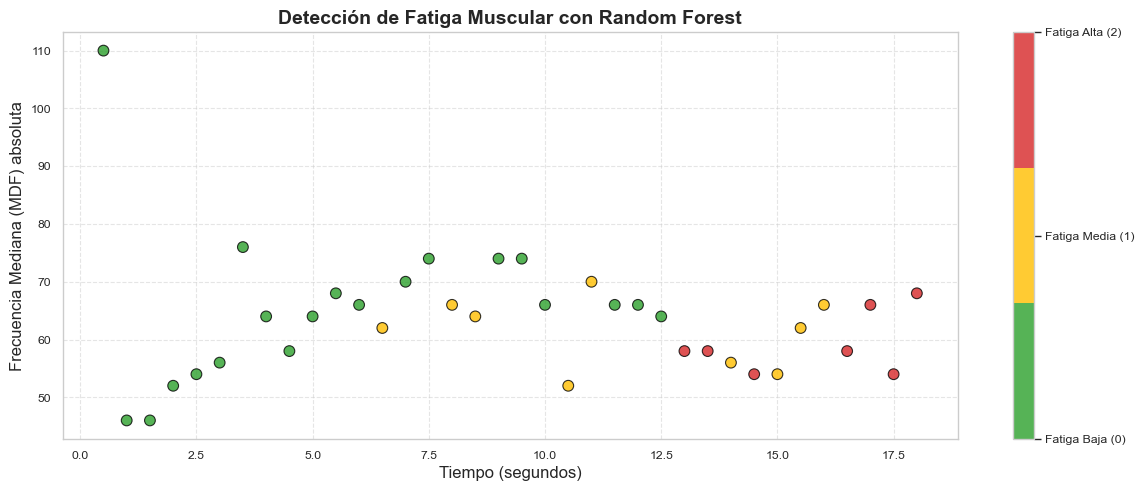

In [22]:
import pandas as pd
import joblib
import matplotlib.pyplot as plt
from matplotlib.colors import ListedColormap

def predecir_nivel_fatiga(ruta_csv_nueva_senal, ruta_modelo='modelo_fatiga_rf.pkl'):
    # 1. Cargar el modelo Random Forest previamente entrenado
    rf_cargado = joblib.load(ruta_modelo)
    
    # 2. Cargar la nueva señal fisiológica de forma robusta
    # Intentamos primero con coma, si no encuentra 'time_s', intentamos con punto y coma
    df_nuevo = pd.read_csv(ruta_csv_nueva_senal)
    
    # Limpiar espacios en blanco accidentales en los nombres de las columnas
    df_nuevo.columns = df_nuevo.columns.str.strip()
    
    if 'time_s' not in df_nuevo.columns:
        df_nuevo = pd.read_csv(ruta_csv_nueva_senal, sep=';')
        df_nuevo.columns = df_nuevo.columns.str.strip()

    # Ordenar por tiempo
    df_nuevo = df_nuevo.sort_values('time_s').reset_index(drop=True)
    
    # Rellenar posibles nulos en la asimetría bilateral (valores por defecto de reposo)
    # Por si tu archivo nuevo no tiene esas columnas, las creamos por defecto para que el modelo no falle
    if 'RMS_ratio_dr_iz' not in df_nuevo.columns:
        df_nuevo['RMS_ratio_dr_iz'] = 1.0
    else:
        df_nuevo['RMS_ratio_dr_iz'] = df_nuevo['RMS_ratio_dr_iz'].fillna(1.0)
        
    if 'MDF_diff_dr_iz' not in df_nuevo.columns:
        df_nuevo['MDF_diff_dr_iz'] = 0.0
    else:
        df_nuevo['MDF_diff_dr_iz'] = df_nuevo['MDF_diff_dr_iz'].fillna(0.0)

    # 3. Feature Engineering Automático (Z-Score y variables temporales)
    cols_to_norm = ['RMS', 'MAV', 'WL', 'MDF', 'MNF']
    for col in cols_to_norm:
        df_nuevo[f'{col}_z'] = (df_nuevo[col] - df_nuevo[col].mean()) / df_nuevo[col].std()
        
    for col in ['RMS', 'MDF']:
        df_nuevo[f'{col}_slope'] = df_nuevo[col].diff().fillna(0)
        
    for col in ['MDF_z', 'RMS_z']:
        df_nuevo[f'{col}_roll10'] = df_nuevo[col].rolling(10, min_periods=1).mean()
        
    # 4. Seleccionar las características en el orden exacto que requiere el modelo
    features = ['RMS_ratio_dr_iz', 'MDF_diff_dr_iz'] + \
               [f'{c}_z' for c in cols_to_norm] + \
               ['RMS_slope', 'MDF_slope', 'MDF_z_roll10', 'RMS_z_roll10']
               
    X_nuevo = df_nuevo[features]
    
    # 5. ¡Predecir el nivel de fatiga!
    df_nuevo['fatiga_predicha'] = rf_cargado.predict(X_nuevo)
    
    # 6. Graficar los resultados
    plt.figure(figsize=(12, 5))
    
    # Colores: Verde (Baja), Amarillo (Media), Rojo (Alta)
    colores = ListedColormap(['#2ca02c', '#ffbf00', '#d62728'])
    
    scatter = plt.scatter(df_nuevo['time_s'], df_nuevo['MDF'], 
                          c=df_nuevo['fatiga_predicha'], 
                          cmap=colores, s=60, edgecolor='black', alpha=0.8)
    
    plt.title('Detección de Fatiga Muscular con Random Forest', fontsize=14, fontweight='bold')
    plt.xlabel('Tiempo (segundos)', fontsize=12)
    plt.ylabel('Frecuencia Mediana (MDF) absoluta', fontsize=12)
    
    cbar = plt.colorbar(scatter, ticks=[0, 1, 2])
    cbar.ax.set_yticklabels(['Fatiga Baja (0)', 'Fatiga Media (1)', 'Fatiga Alta (2)'])
    
    plt.grid(True, linestyle='--', alpha=0.5)
    plt.tight_layout()
    plt.show()
    
    return df_nuevo

# ==========================================
# --- ORDEN DE EJECUCIÓN ---
# ==========================================
print("Iniciando carga de datos y predicción...")

resultados = predecir_nivel_fatiga('features_nuevo_paciente.csv')



In [ ]:
# --- REPORTE CLÍNICO ---

def analizar_resultados_fatiga(df_resultados):
    total_ventanas = len(df_resultados)
    tiempo_total = df_resultados['time_s'].max()
    
    # Conteo de ventanas por clase
    conteos = df_resultados['fatiga_predicha'].value_counts().to_dict()
    ventanas_0 = conteos.get(0, 0)
    ventanas_1 = conteos.get(1, 0)
    ventanas_2 = conteos.get(2, 0)
    
    # Porcentajes de tiempo en cada estado
    pct_0 = (ventanas_0 / total_ventanas) * 100
    pct_1 = (ventanas_1 / total_ventanas) * 100
    pct_2 = (ventanas_2 / total_ventanas) * 100
    
    # Detectar el momento exacto de inicio de la fatiga severa (Clase 2)
    df_fatiga_severa = df_resultados[df_resultados['fatiga_predicha'] == 2]
    
    print("==========================================================")
    print("📊 REPORTE NUMÉRICO DEL PACIENTE")
    print("==========================================================")
    print(f"⏱️ Duración total de la prueba analizada: {tiempo_total:.2f} segundos")
    print(f"🟢 Estado Basal / Baja Fatiga (Clase 0) : {pct_0:.1f}% del tiempo")
    print(f"🟡 Transición / Fatiga Media (Clase 1)  : {pct_1:.1f}% del tiempo")
    print(f"🔴 Fallo / Fatiga Severa (Clase 2)      : {pct_2:.1f}% del tiempo")
    
    print("\n==========================================================")
    print("📝 ANÁLISIS CUALITATIVO / FISIOLÓGICO AUTOMATIZADO")
    print("==========================================================")
    
    if not df_fatiga_severa.empty:
        # Extraer el segundo exacto donde aparece el primer nivel de clase 2
        inicio_clase_2 = df_fatiga_severa['time_s'].iloc[0]
        
        print(f"El músculo recto femoral del sujeto inició la prueba en un estado de bajo "
              f"reclutamiento compensatorio. Sin embargo, a los {inicio_clase_2:.2f} segundos, el algoritmo detectó "
              f"la transición fisiológica hacia una fatiga periférica aguda (Clase 2).")
        print(f"")
        print(f"A partir de este umbral, los marcadores espectrales indican una acumulación crítica "
              f"de metabolitos que provocan una caída en la velocidad de conducción de los potenciales "
              f"de acción de las unidades motoras. El sistema nervioso central se vio obligado a "
              f"activar mecanismos de compensación neuromuscular extremos para mantener el torque "
              f"mecánico requerido por la máquina de extensión. El paciente permaneció el {pct_2:.1f}% "
              f"del ejercicio en este estado crítico antes de la detención.")
    else:
        print(f"Durante los {tiempo_total:.2f} segundos de la prueba, el sujeto no alcanzó el umbral "
              f"electromiográfico de fatiga severa (Clase 2). Las características matemáticas sugieren "
              f"una alta resistencia a la carga sub-máxima del 70% del 1RM, logrando mantener una "
              f"velocidad de conducción muscular estable sin requerir reclutamiento extremo.")
    print("==========================================================")

# --- EJECUTAR EL ANÁLISIS ---
# Llamamos a la función usando la variable 'resultados' que generó tu gráfica anterior
analizar_resultados_fatiga(resultados)

📊 REPORTE NUMÉRICO DEL PACIENTE
⏱️ Duración total de la prueba analizada: 18.00 segundos
🟢 Estado Basal / Baja Fatiga (Clase 0) : 55.6% del tiempo
🟡 Transición / Fatiga Media (Clase 1)  : 25.0% del tiempo
🔴 Fallo / Fatiga Severa (Clase 2)      : 19.4% del tiempo

📝 ANÁLISIS CUALITATIVO / FISIOLÓGICO AUTOMATIZADO
El músculo recto femoral del sujeto inició la prueba en un estado de bajo reclutamiento compensatorio. Sin embargo, a los 13.00 segundos, el algoritmo detectó la transición fisiológica hacia una fatiga periférica aguda (Clase 2).

A partir de este umbral, los marcadores espectrales indican una acumulación crítica de metabolitos que provocan una caída en la velocidad de conducción de los potenciales de acción de las unidades motoras. El sistema nervioso central se vio obligado a activar mecanismos de compensación neuromuscular extremos para mantener el torque mecánico requerido por la máquina de extensión. El paciente permaneció el 19.4% del ejercicio en este estado crítico ante